# 03 - Data Preparation

**Question:** how do the two recordings become one analysable time base, and which units of analysis (stop
windows, pallet cycles, activations) does the modelling need?

| Part | Content | Source |
|---|---|---|
| 1 | Time overlap and the common time grid | team notebook `02_pre_processing` (original code) |
| 2 | Clock offset: activity correlation, then the direct hand-shake test (H1) | team pre-processing, v1 H1, extension |
| 3 | Merge both PLCs on the 50 ms grid, with a check | team pre-processing |
| 4 | Raw rows or the 50 ms grid -> decision | extension |
| 5 | Stop windows and line standstill | extension |
| 6 | Pallet cycles (H2) and the serial warehouse + robot chain | v1 H2, extension |
| 7 | The activation table - the input of both models; the material flow of one cycle | v1 step 3.1 |

Input: `data/processed/02_data.pkl`. Output: `data/processed/03_prepared.pkl` (stop windows, cycles, activations,
time-base limits) for notebooks 04-06.

## Setup

Imports, parameters (the same values as `config.yaml`) and the hand-over of results between the notebooks (`data/processed/`, run the notebooks in order 01-06).

In [1]:
from io import StringIO
from pathlib import Path

from IPython.display import Image, display
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
import re
from scipy import stats as sps
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import dataclasses
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [2]:
# Parameters - the same values as config.yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = {'paths': {'raw_siemens': 'data/raw/Beispieldatensatz Siemens S7 SPS.csv',
           'raw_beckhoff': 'data/raw/Beispieldatensatz Beckhoff SPS.csv',
           'variable_file': 'data/raw/Variablenerklärung.xlsx',
           'reports_dir': 'reports',
           'figures_dir': 'reports/figures'},
 'timebase': {'gap_report_s': 0.5,
              'gap_cooccur_tolerance_s': 0.2,
              'resample_grids_ms': [20, 50, 76, 93, 100, 200, 500]},
 'phases': {'production_start_signal': 'E200.0',
            'curtain_signal': 'A201.0',
            'curtain_signal_beckhoff': 'VG.safeCurtainShort',
            'hmi_run_signal': 'Visual.start',
            'pallet_request_signals': ['WH.desiredPalletX', 'WH.desiredPalletY'],
            'drilling_cycle_register': 'MW22'},
 'rule': {'tukey_k': 3.0,
          'min_activations': 5,
          'min_excess_s': 'auto',
          'sweep_k': [1.5, 3.0],
          'sweep_min_excess_s': [1.0, 1.5, 1.84, 2.0, 2.5, 3.0, 4.0, 5.0],
          'sweep_merge_gap_s': [0.0, 1.0, 2.0, 5.0, 10.0],
          'merge_gap_s': 0.0},
 'ml': {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        'contamination_sweep': [0.01, 0.02, 0.05, 0.1],
        'kmeans_k': [2, 3, 4, 5, 6, 7, 8],
        'top_k': 10},
 'performance': {'bootstrap_resamples': 5000, 'bootstrap_seed': 42}}
cfg["paths"] = {k: ROOT / v for k, v in cfg["paths"].items()}
PROCESSED = ROOT / "data" / "processed"        # prepared data handed from one notebook to the next
FIGURES = cfg["paths"]["figures_dir"]          # reports/figures

In [3]:
def save_stage(name, results):
    """Write this notebook's results to data/processed/<name>.pkl for the next notebooks."""
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(results, PROCESSED / f"{name}.pkl")


def load_stage(name, notebook):
    """Results of an earlier notebook; a clear message names the notebook to run first."""
    f = PROCESSED / f"{name}.pkl"
    if not f.exists():
        raise FileNotFoundError(f"data/processed/{name}.pkl is missing - run notebook {notebook} first.")
    return pd.read_pickle(f)

**Data container**

- `PLCData`: Analysis-ready recording of one PLC.

In [4]:
@dataclass
class PLCData:
    """Analysis-ready recording of one PLC."""

    name: str
    frame: pd.DataFrame                 # timestamp, t, one column per signal
    signals: list[str]
    raw_shape: tuple[int, int]          # rows, signal columns (as in the file)
    excluded_rows: pd.DataFrame = field(default_factory=pd.DataFrame)
    dropped_columns: list[str] = field(default_factory=list)

In [5]:
s02 = load_stage("02_data", "02_data_understanding_and_cleaning")
data = {k: PLCData(**v) if k in ("Siemens", "Beckhoff") else v for k, v in s02.pop("data").items()}
samp = s02["sampling"]
limit = float(samp["max_step_s"].max())     # detection limit: largest logging step (notebook 02, part 4)
tol = float(samp["median_step_s"].sum())    # cross-PLC tolerance: one median step of each PLC

## Part 1 - Time overlap and the common time grid

*Source: team notebook `02_pre_processing` - original code. Changed: the cleaned frames come from memory instead of
`data/processed/`, the `%pip install` cell and the file save are removed.*

**Goal:** prepare the two cleaned datasets so they can be merged and used for stop detection and modelling.

### Load both cleaned datasets and check the time overlap

Both cleaned files are loaded. For each PLC the first time, last time, duration and median logging interval are
printed. The overlap of the two recordings is calculated, because only the overlapping part can be merged. If
there is no overlap, the merge is impossible.

======================================== SIEMENS ========================================
Shape: (6282, 143)
First time: 2019-09-26 18:21:14.515000+00:00
Last time:  2019-09-26 18:29:40.213000+00:00
Duration (s): 505.698
Median interval (ms): 76.0
======================================== BECKHOFF ========================================
Shape: (5197, 54)
First time: 2019-09-26 18:21:14.925000+00:00
Last time:  2019-09-26 18:29:40.319000+00:00
Duration (s): 505.394
Median interval (ms): 93.0

======================================== OVERLAP ========================================
Overlap start: 2019-09-26 18:21:14.925000+00:00
Overlap end:   2019-09-26 18:29:40.213000+00:00
Overlap duration (s): 505.288


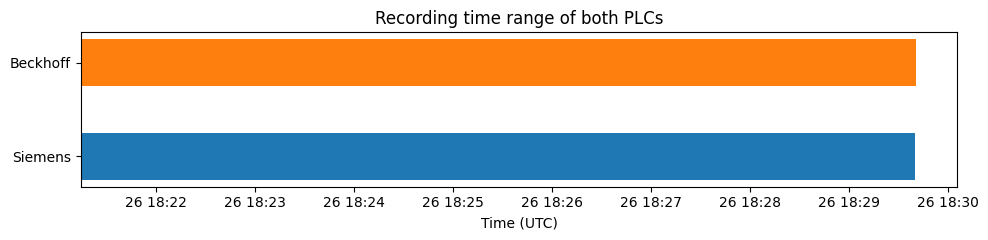

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# the cleaned data of notebook 02 (identical to the team's cleaned files), from memory
siemens_clean = data["Siemens"].frame[["timestamp"] + data["Siemens"].signals].copy()
beckhoff_clean = data["Beckhoff"].frame[["timestamp"] + data["Beckhoff"].signals].copy()

# Time range of each PLC
for name, df in [("SIEMENS", siemens_clean), ("BECKHOFF", beckhoff_clean)]:
    ts = df["timestamp"]
    print("=" * 40, name, "=" * 40)
    print("Shape:", df.shape)
    print("First time:", pd.to_datetime(ts.iloc[0], unit="ms", utc=True))
    print("Last time: ", pd.to_datetime(ts.iloc[-1], unit="ms", utc=True))
    print("Duration (s):", (ts.iloc[-1] - ts.iloc[0]) / 1000)
    print("Median interval (ms):", ts.diff().median())

# Overlap of the two recordings
overlap_start = max(siemens_clean["timestamp"].iloc[0], beckhoff_clean["timestamp"].iloc[0])
overlap_end = min(siemens_clean["timestamp"].iloc[-1], beckhoff_clean["timestamp"].iloc[-1])
overlap_seconds = (overlap_end - overlap_start) / 1000

print("\n" + "=" * 40, "OVERLAP", "=" * 40)
print("Overlap start:", pd.to_datetime(overlap_start, unit="ms", utc=True))
print("Overlap end:  ", pd.to_datetime(overlap_end, unit="ms", utc=True))
print("Overlap duration (s):", overlap_seconds)

# Plot: both recordings on one time axis
fig, ax = plt.subplots(figsize=(10, 2.5))
for row, (name, df) in enumerate([("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]):
    start = pd.to_datetime(df["timestamp"].iloc[0], unit="ms", utc=True)
    end = pd.to_datetime(df["timestamp"].iloc[-1], unit="ms", utc=True)
    ax.barh(row, end - start, left=start, height=0.5, label=name)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Siemens", "Beckhoff"])
ax.set_xlabel("Time (UTC)")
ax.set_title("Recording time range of both PLCs")
plt.tight_layout()
plt.show()

### Choose the common time grid

#### Summary

The two PLCs log at different, irregular intervals, so both must be put on one regular time grid before merging. If the grid is too coarse, a short ON pulse that starts and ends between two grid points disappears. For each PLC and for grid sizes of 20, 50, 100 and 200 ms, the boolean signals are resampled (each grid point takes the last known value, no interpolation), and the ON/OFF changes before and after are counted. The loss in percent shows how much information each grid destroys.

Siemens: 125 boolean signals, 2023.0 changes in the raw data
Beckhoff: 50 boolean signals, 4438.0 changes in the raw data

Lost signal changes (%):
         Siemens  Beckhoff
grid_ms                   
20          0.00      0.00
50          0.00      0.00
100         7.02      4.01
200        18.49     33.66


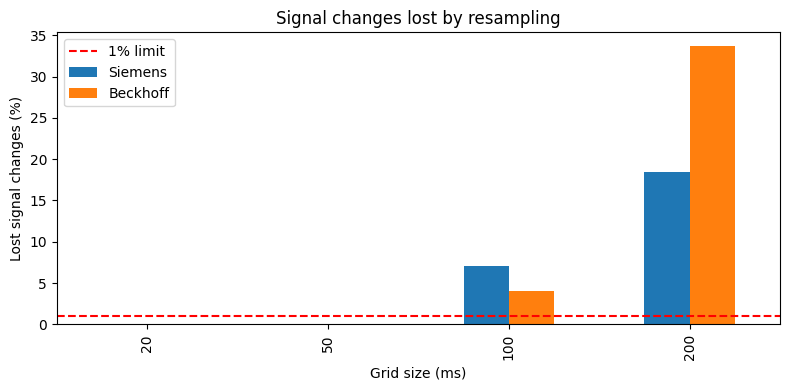

Coarsest grid with loss < 1% in both PLCs: 50


In [7]:
import numpy as np

grid_sizes = [20, 50, 100, 200]          # candidate grid sizes in ms
loss_table = pd.DataFrame(index=grid_sizes, columns=["Siemens", "Beckhoff"], dtype=float)
loss_table.index.name = "grid_ms"

for name, df in [("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]:
    # only boolean signals: count their ON/OFF changes
    signals = df.drop(columns="timestamp").select_dtypes(include="bool")
    edges_raw = signals.astype(int).diff().abs().sum().sum()
    ts = df["timestamp"].values

    for step in grid_sizes:
        grid = np.arange(ts[0], ts[-1], step)
        # last known value at each grid point (forward fill, no interpolation)
        position = np.searchsorted(ts, grid, side="right") - 1
        edges_grid = signals.iloc[position].astype(int).diff().abs().sum().sum()
        loss_table.loc[step, name] = (edges_raw - edges_grid) / edges_raw * 100

    print(f"{name}: {signals.shape[1]} boolean signals, {edges_raw} changes in the raw data")

print("\nLost signal changes (%):")
print(loss_table.round(2).to_string())

# Plot
ax = loss_table.plot(kind="bar", figsize=(8, 4))
ax.axhline(1, color="red", linestyle="--", label="1% limit")
ax.set_xlabel("Grid size (ms)")
ax.set_ylabel("Lost signal changes (%)")
ax.set_title("Signal changes lost by resampling")
ax.legend()
plt.tight_layout()
plt.show()

# Decision rule: coarsest grid with loss < 1% in both PLCs
accepted = loss_table[(loss_table < 1).all(axis=1)]
print("Coarsest grid with loss < 1% in both PLCs:",
      accepted.index.max() if not accepted.empty else "none")

**Transition loss of every configured grid**

- `edge_times`: Times at which ``x`` changes value (time of the first new sample).
- `resample_loss`: How many boolean transitions survive on a regular last-value grid.

In [8]:
def edge_times(t, x) -> np.ndarray:
    """Times at which ``x`` changes value (time of the first new sample)."""
    x = np.asarray(x)
    return np.asarray(t, dtype=float)[1:][x[1:] != x[:-1]]


def resample_loss(plcs: dict, grids_ms: list[int]) -> pd.DataFrame:
    """How many boolean transitions survive on a regular last-value grid.

    For each grid the value of every boolean signal at each grid tick is the
    last logged value at or before the tick (what pandas ``asfreq``/``ffill``
    or ``merge_asof`` would produce). Lost transitions are short pulses that
    fall between two ticks. Edge time error is the shift of surviving edges.
    """
    rows = []
    for g in grids_ms:
        step = g / 1000.0
        total = kept = lost_pulses = 0
        shift = []
        for name in ("Siemens", "Beckhoff"):
            d = plcs[name]
            t = d.frame["t"].to_numpy()
            ticks = np.arange(t[0], t[-1] + 1e-9, step)
            pos = np.searchsorted(t, ticks, side="right") - 1
            for sig in d.signals:
                v = d.frame[sig]
                if v.dtype != bool or v.nunique() < 2:
                    continue
                v = v.to_numpy()
                raw_edges = int((v[1:] != v[:-1]).sum())
                r = v[pos]
                grid_edges_idx = np.flatnonzero(r[1:] != r[:-1]) + 1
                total += raw_edges
                kept += len(grid_edges_idx)
                lost_pulses += (raw_edges - len(grid_edges_idx)) // 2
                raw_t = edge_times(t, v)
                if len(grid_edges_idx) and len(raw_t):
                    gt = ticks[grid_edges_idx]
                    j = np.clip(np.searchsorted(raw_t, gt, side="right") - 1, 0, len(raw_t) - 1)
                    shift.extend(gt - raw_t[j])
        rows.append({
            "grid_ms": g, "raw_transitions": total, "grid_transitions": kept,
            "lost_transitions": total - kept,
            "lost_pct": 100.0 * (total - kept) / total,
            "lost_pulses": lost_pulses,
            "median_edge_shift_s": float(np.median(shift)) if shift else np.nan,
            "max_edge_shift_s": float(np.max(shift)) if shift else np.nan,
        })
    return pd.DataFrame(rows)

In [9]:
resample = resample_loss(data, cfg["timebase"]["resample_grids_ms"])
resample

,grid_ms,raw_transitions,grid_transitions,lost_transitions,lost_pct,lost_pulses,median_edge_shift_s,max_edge_shift_s
0,20,6461,6461,0,0.000000,0,0.009,0.019
1,50,6461,6461,0,0.000000,0,0.025,0.050
2,76,6461,6457,4,0.061910,2,0.038,0.076
3,93,6461,6309,152,2.352577,76,0.048,0.093
4,100,6461,6141,320,4.952794,160,0.050,0.099
5,200,6461,4593,1868,28.911933,934,0.099,0.199
6,500,6461,3549,2912,45.070423,1456,0.236,0.498


## Part 2 - Clock offset between the PLCs (H1)

### Team: clock offset from the activity correlation

#### Summary

Each PLC records timestamps using its own clock. If the clocks are not synchronized, the same physical event can have different timestamps in the two datasets.

Both PLCs are aligned to the common 50 ms time grid selected in Step 2. For each PLC, the number of signal changes per grid step (activity) is calculated.

The Siemens activity curve is shifted against the Beckhoff activity curve from -2 seconds to +2 seconds. The correlation is calculated for each shift. The shift with the highest correlation is taken as the estimated clock offset.

Best shift (steps): 40
Estimated offset (ms): 2000
Correlation at best shift: 0.024
Correlation at shift 0: 0.003
Typical (median) correlation: -0.001
Within one grid step (no correction needed): False


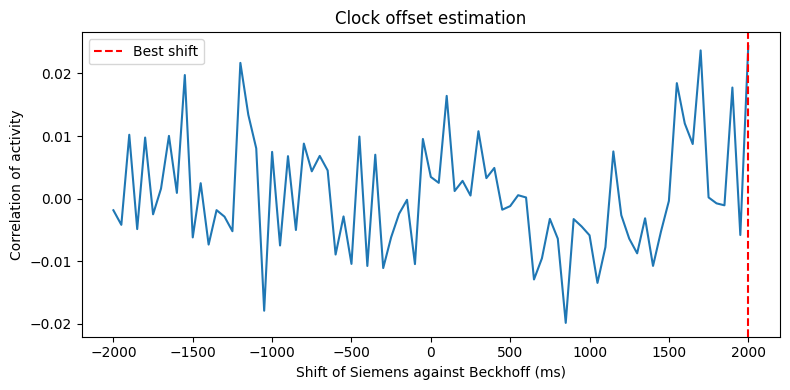

In [10]:
# Step 3: Estimate clock offset between Siemens and Beckhoff

grid_ms = 50  # Selected common grid from Step 2
grid = np.arange(overlap_start, overlap_end, grid_ms)

# Check that timestamps are sorted
siemens_clean = siemens_clean.sort_values("timestamp").reset_index(drop=True)
beckhoff_clean = beckhoff_clean.sort_values("timestamp").reset_index(drop=True)

# Calculate activity (number of signal changes per grid step)
activity = {}

for name, df in [("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]:

    signals = df.drop(columns="timestamp").select_dtypes(include="bool")

    ts = df["timestamp"].values

    position = np.searchsorted(ts, grid, side="right") - 1

    # Last known signal value at each grid point
    sampled = signals.iloc[position].astype(int)

    # Count signal changes per grid step
    changes = sampled.diff().abs().sum(axis=1).fillna(0)

    activity[name] = changes.values

# Correlation for shifts from -2 seconds to +2 seconds
max_lag = 40  # 40 x 50 ms = 2 seconds

lags = list(range(-max_lag, max_lag + 1))
corr = []

for lag in lags:

    if lag >= 0:
        a = activity["Siemens"][lag:]
        b = activity["Beckhoff"][:len(activity["Beckhoff"]) - lag]
    else:
        a = activity["Siemens"][:lag]
        b = activity["Beckhoff"][-lag:]

    # Avoid correlation when there is no variation
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        corr.append(np.nan)
    else:
        corr.append(np.corrcoef(a, b)[0, 1])

# Find shift with highest valid correlation
corr = np.array(corr)

if not np.isfinite(corr).any():
    raise ValueError("Could not calculate valid correlations.")

best_index = np.nanargmax(corr)
best_lag = lags[best_index]

print("Best shift (steps):", best_lag)
print("Estimated offset (ms):", best_lag * grid_ms)
print("Correlation at best shift:", round(corr[best_index], 3))
print("Correlation at shift 0:", round(corr[max_lag], 3))
print("Typical (median) correlation:", round(float(np.nanmedian(corr)), 3))
print("Within one grid step (no correction needed):", abs(best_lag) <= 1)

# Plot correlation against time shift
plt.figure(figsize=(8, 4))

plt.plot([lag * grid_ms for lag in lags], corr)
plt.axvline(best_lag * grid_ms, color="red",
            linestyle="--", label="Best shift")

plt.xlabel("Shift of Siemens against Beckhoff (ms)")
plt.ylabel("Correlation of activity")
plt.title("Clock offset estimation")

plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Inspect activity patterns

for name in ["Siemens", "Beckhoff"]:

    values = activity[name]

    print(f"\n===== {name} =====")

    print("Total grid points:", len(values))
    print("Total signal changes:", np.sum(values))
    print("Mean activity:", np.mean(values))
    print("Standard deviation:", np.std(values))
    print("Maximum activity:", np.max(values))
    print("Percentage of zero activity:",
          np.mean(values == 0) * 100)


===== Siemens =====
Total grid points: 10106
Total signal changes: 2023.0
Mean activity: 0.20017811201266575
Standard deviation: 0.8500264649026334
Maximum activity: 14.0
Percentage of zero activity: 90.8074411240847

===== Beckhoff =====
Total grid points: 10106
Total signal changes: 4438.0
Mean activity: 0.4391450623392044
Standard deviation: 0.9961867833872668
Maximum activity: 8.0
Percentage of zero activity: 76.14288541460519


#### Conclusion – Clock Offset Estimation

The activity-based correlation analysis did not reveal a meaningful relationship between Siemens and Beckhoff activity patterns. The maximum correlation was only 0.024, indicating that a reliable clock offset could not be estimated using this method.

Therefore, no timestamp correction is applied. We proceed with merging both datasets using the common 50 ms time grid, while noting that clock synchronization could not be independently verified.

### Why the activity correlation found nothing - and a direct test

**Why the activity correlation found nothing.** It compares *how much* each PLC switches over time. The Siemens PLC
runs the drilling / sorting half, the Beckhoff PLC the warehouse / robot half; their activity does not have to rise
and fall together. A missing correlation is therefore *no evidence of an offset* - the method simply has no common
signal to lock on.

**A common signal exists** (team v1 analysis, step 2.6 - original code): the Siemens output `A201.0` is
**documented** as "Safetydata from curtain to beckhoff". The Beckhoff input `VG.safeCurtainShort` switches at the
same moments. If the clocks agree, each edge appears in both files at the same time, within the sync tolerance.

**Edge functions**

- `on_intervals`: (start, end) of every period in which boolean ``x`` is True.

In [12]:
def on_intervals(t, x) -> list[tuple[float, float]]:
    """(start, end) of every period in which boolean ``x`` is True.

    start = time of the first True sample; end = time of the first False
    sample afterwards, or the last sample if still True at the end.
    """
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b])) for a, b in zip(starts, ends)]

In [13]:
sie, bec = data["Siemens"].frame, data["Beckhoff"].frame
SYNC_TOLERANCE_S = tol

In [14]:
sie_edges = edge_times(sie["t"], sie["A201.0"])
bec_edges = edge_times(bec["t"], bec["VG.safeCurtainShort"])
if len(sie_edges) != len(bec_edges):
    raise ValueError("The two safety signals do not have the same edges.")

clock = pd.DataFrame({
    "Siemens_A201.0_s": sie_edges,
    "Beckhoff_safeCurtainShort_s": bec_edges,
})
clock["difference_s"] = clock.iloc[:, 1] - clock.iloc[:, 0]
print(clock.round(3).to_string(index=False))

max_offset = clock["difference_s"].abs().max()
H1_ACCEPTED = bool(max_offset <= SYNC_TOLERANCE_S)
print(f"\nLargest difference: {max_offset:.3f} s "
      f"(tolerance {SYNC_TOLERANCE_S:.3f} s) -> H1 accepted: {H1_ACCEPTED}")

 Siemens_A201.0_s  Beckhoff_safeCurtainShort_s  difference_s
            8.851                        8.882         0.031
          255.396                      255.487         0.091
          264.292                      264.263        -0.029
          390.061                      390.100         0.039
          400.438                      400.396        -0.042
          453.141                      453.190         0.049
          460.743                      460.772         0.029

Largest difference: 0.091 s (tolerance 0.169 s) -> H1 accepted: True


**Result H1 (measured):** all 7 edges appear in both files, at most
0.09 s apart, which is within the sync tolerance of 0.169 s. The
differences change sign (the clocks do not drift apart). **H1 is
accepted:** no clock correction is needed, and Siemens and Beckhoff
events can be compared directly.

**What each edge pair bounds.** Each logged edge lies within one logging step after the true edge, so each pair of
edges gives an interval for (Beckhoff clock - Siemens clock + transmission delay); the true value lies in all
intervals (function `cross_plc_sync`):

**Hand-shake bound**

- `step_before`: Logging step that ends at the sample logged at ``time``.
- `cross_plc_sync`: Edges of the documented Siemens->Beckhoff safety signal in both logs.
- `sync_summary`: Offset consistent with all handshake edges (interval intersection).

In [15]:
def step_before(t: np.ndarray, time: float) -> float:
    """Logging step that ends at the sample logged at ``time``.

    An edge logged at ``time`` happened somewhere in (time - step, time], so
    this is the timing uncertainty of that edge.
    """
    t = np.asarray(t, dtype=float)
    i = int(np.clip(np.searchsorted(t, time), 1, len(t) - 1))
    return float(t[i] - t[i - 1])


def cross_plc_sync(plcs: dict, sie_signal: str, bec_signal: str) -> pd.DataFrame:
    """Edges of the documented Siemens->Beckhoff safety signal in both logs.

    ``A201.0`` is documented as "Safetydata from curtain to beckhoff"; the
    Beckhoff input ``VG.safeCurtainShort`` receives it. The same physical edge
    therefore appears in both files.
    """
    s = plcs["Siemens"].frame
    b = plcs["Beckhoff"].frame
    es = edge_times(s["t"], s[sie_signal].to_numpy())
    eb = edge_times(b["t"], b[bec_signal].to_numpy())
    if len(es) != len(eb):
        raise ValueError("handshake signals have different edge counts")
    out = pd.DataFrame({"siemens_edge_s": es, "beckhoff_edge_s": eb})
    out["direction"] = ["falling" if not s[sie_signal].to_numpy()[np.searchsorted(s["t"], x)]
                        else "rising" for x in es]
    out["siemens_step_s"] = [step_before(s["t"].to_numpy(), x) for x in es]
    out["beckhoff_step_s"] = [step_before(b["t"].to_numpy(), x) for x in eb]
    out["difference_s"] = out["beckhoff_edge_s"] - out["siemens_edge_s"]
    # Each logged edge lies in (logged - step, logged]; the true offset
    # interval implied by each pair:
    out["offset_low_s"] = out["difference_s"] - out["beckhoff_step_s"]
    out["offset_high_s"] = out["difference_s"] + out["siemens_step_s"]
    return out


def sync_summary(sync: pd.DataFrame) -> dict:
    """Offset consistent with all handshake edges (interval intersection)."""
    lo = float(sync["offset_low_s"].max())
    hi = float(sync["offset_high_s"].min())
    return {
        "n_edges": int(len(sync)),
        "max_abs_difference_s": float(sync["difference_s"].abs().max()),
        "median_difference_s": float(sync["difference_s"].median()),
        "feasible_offset_low_s": lo,
        "feasible_offset_high_s": hi,
        "zero_offset_feasible": bool(lo <= 0.0 <= hi),
        "differences_change_sign": bool((sync["difference_s"] > 0).any()
                                        and (sync["difference_s"] < 0).any()),
    }

In [16]:
sync = cross_plc_sync(data, cfg["phases"]["curtain_signal"], cfg["phases"]["curtain_signal_beckhoff"])
display(sync.round(3))
ss = sync_summary(sync)
print(f"offset + transmission delay in [{ss['feasible_offset_low_s']:.3f}, {ss['feasible_offset_high_s']:.3f}] s, "
      f"from {ss['n_edges']} edges between {sync['siemens_edge_s'].min():.0f} s and {sync['siemens_edge_s'].max():.0f} s")
assert np.allclose(sync["difference_s"], clock["difference_s"])     # check: same edges as the v1 cell

,siemens_edge_s,beckhoff_edge_s,direction,siemens_step_s,beckhoff_step_s,difference_s,offset_low_s,offset_high_s
0,8.851,8.882,rising,0.075,0.093,0.031,-0.062,0.106
1,255.396,255.487,falling,0.076,0.092,0.091,-0.001,0.167
2,264.292,264.263,rising,0.076,0.080,-0.029,-0.109,0.047
3,390.061,390.100,falling,0.078,0.095,0.039,-0.056,0.117
4,400.438,400.396,rising,0.079,0.094,-0.042,-0.136,0.037
5,453.141,453.190,falling,0.078,0.096,0.049,-0.047,0.127
6,460.743,460.772,rising,0.076,0.095,0.029,-0.066,0.105


offset + transmission delay in [-0.001, 0.037] s, from 7 edges between 9 s and 461 s


**What this proves:** during the curtain stops (the time span printed above) the two clocks differ by less than
about 0.04 s, *if* the transmission delay from `A201.0` to `VG.safeCurtainShort` is negligible. Zero offset is
consistent with all edges.

**What it does not prove:**

* anything outside that time span - drift before the first or after the last curtain stop is untested;
* the offset alone: a constant transmission delay d cannot be separated from the offset;
* more than one signal path - only one documented hand-shake exists;
* that both files come from one shared logger (coinciding logging gaps make it likely, not certain).

**Does it matter?** Event detection compares durations *within* one PLC, so a clock offset can only shift
cross-PLC timing statements (e.g. "abnormal 3.0 s before the stop"). The clock-shift test (shift the Beckhoff
clock on purpose and re-run the detection) needs the Model 1 rule, so it is part of the robustness checks in
notebook 04.

**Conclusion (H1):** synchronisation is *supported within the tested span*; notebook 04 shows that even a 1 s
clock shift (25 times the measured bound) leaves every event in place. It is not proven for the whole
recording. No correction is applied; cross-PLC comparisons use the tolerance `tol`.

## Part 3 - Merge both PLCs on the 50 ms grid

*Source: team notebook `02_pre_processing`, Step 4 - original code, without the file save.*

Both PLC datasets are aligned to the common 50 ms time grid. The last available observation is carried forward to
each grid point without interpolation. The two datasets are then merged using their common timestamps. Siemens and
Beckhoff signal columns are given separate prefixes to identify their source and avoid duplicate column names.

In [17]:
# Step 4: Merge Siemens and Beckhoff datasets

grid_ms = 50
grid = np.arange(overlap_start, overlap_end, grid_ms)


# Function to align each PLC dataset to the common grid
def align_to_grid(df, name):

    df = df.sort_values("timestamp").reset_index(drop=True)

    ts = df["timestamp"].values

    # Find the last available observation at each grid point
    position = np.searchsorted(ts, grid, side="right") - 1

    if np.any(position < 0):
        raise ValueError(f"{name}: Grid contains timestamps before available data.")

    # Sample all signal columns at the grid positions
    aligned = df.drop(columns="timestamp").iloc[position].reset_index(drop=True)

    # Add PLC prefix to signal names
    aligned.columns = [f"{name}_{col}" for col in aligned.columns]

    # Add common timestamp
    aligned.insert(0, "timestamp", grid)

    return aligned


# Align both PLC datasets
siemens_aligned = align_to_grid(siemens_clean, "Siemens")
beckhoff_aligned = align_to_grid(beckhoff_clean, "Beckhoff")


# Merge using the common timestamp
merged = pd.merge(
    siemens_aligned,
    beckhoff_aligned,
    on="timestamp",
    how="inner"
)


# Sort by timestamp
merged = merged.sort_values("timestamp").reset_index(drop=True)


# Display results
print("Merged dataset shape:", merged.shape)
print("\nFirst 5 rows:")
display(merged.head())

print("\nMissing values:")
print(merged.isna().sum().sum())

Merged dataset shape: (10106, 196)

First 5 rows:


,timestamp,Siemens_M34.4,Siemens_M24.7,Siemens_M25.3,Siemens_M25.4,Siemens_I200.7,Siemens_M38.0,Siemens_M38.1,Siemens_A0.1,Siemens_A0.0,Siemens_M1.0,Siemens_M1.1,Siemens_C0,Siemens_EW288,Siemens_MW16,Siemens_M0.4,Siemens_M1.2,Siemens_MW12,Siemens_MW14,Siemens_MW18,...,Beckhoff_WH.Q7_cantForw,Beckhoff_WH.Q7_cantilever_forward,Beckhoff_WH.Q8_cantBack,Beckhoff_WH.Q8_cantilever_backward,Beckhoff_WH.Q1_beltForward,Beckhoff_WH.Q2_beltBackward,Beckhoff_VG.Q1_verUp,Beckhoff_VG.Q2_verDown,Beckhoff_VG.Q3_horBack,Beckhoff_VG.Q4_horForw,Beckhoff_VG.Q5_rotClockwise,Beckhoff_VG.Q6_rotCounterClockwise,Beckhoff_VG.Q7_compressorON,Beckhoff_VG.Q8_valve,Beckhoff_Pallets.Conveyor_belt_lift,Beckhoff_VG.atHome,Beckhoff_VG.error_robot,Beckhoff_WH.isEmpty,Beckhoff_WH.desiredPalletX,Beckhoff_WH.desiredPalletY
0,1569522074925,False,False,True,False,False,False,False,False,False,False,False,0.0,0.0,1877.0,False,False,0.0,0.0,0.0,...,False,False,True,False,False,False,False,False,False,False,False,False,False,False,800,False,False,False,1620,110
1,1569522074975,False,False,True,False,False,False,False,False,False,False,False,0.0,0.0,1911.0,False,False,0.0,0.0,0.0,...,False,False,True,False,False,False,False,False,False,False,False,False,False,False,800,False,False,False,1620,110
2,1569522075025,False,False,True,False,False,False,False,False,False,False,False,0.0,0.0,1911.0,False,False,0.0,0.0,0.0,...,False,False,True,False,False,False,False,False,False,False,False,False,False,False,800,False,False,False,1620,110
3,1569522075075,False,False,True,False,False,False,False,False,False,False,False,0.0,0.0,2013.0,False,False,0.0,0.0,0.0,...,False,False,True,False,False,False,False,False,False,False,False,False,False,False,800,False,False,False,1620,110
4,1569522075125,False,False,True,False,False,False,False,False,False,False,False,0.0,0.0,2013.0,False,False,0.0,0.0,0.0,...,False,False,True,False,False,False,False,False,False,False,False,False,False,False,800,False,False,False,1620,110



Missing values:
0


In [18]:
# check: every merged column equals the last logged raw value at each 50 ms tick (no interpolation)
differing = 0
for plc in ("Siemens", "Beckhoff"):
    f = data[plc].frame.drop(columns="t")
    ref = pd.merge_asof(merged[["timestamp"]], f, on="timestamp", direction="backward")
    sig = data[plc].signals
    differing += int((~np.isclose(merged[[f"{plc}_{c}" for c in sig]].astype(float).to_numpy(),
                                  ref[sig].astype(float).to_numpy(), equal_nan=True)).sum())
assert differing == 0
print("merged 50 ms grid == forward-filled raw data:", differing == 0, "| shape", merged.shape)

merged 50 ms grid == forward-filled raw data: True | shape (10106, 196)


## Part 4 - Raw rows or the 50 ms grid?

Part 1 measured lost signal changes. Whether a grid also changes the **losses** found needs the Model 1 rule, so the
event-level grid test is in notebook 04: up to 200 ms the events, their equipment and the stop windows stay the
same; at 500 ms an event is lost and false events appear. The team's 50 ms choice is therefore *confirmed*.

**Decision:** Models 1 and 2 work on the raw logged rows (event time): that needs no grid parameter and keeps every
edge at its logged time. The team's 50 ms merge gives the same losses, so it remains a valid fixed-rate
representation; it is not stored as a file because nothing downstream needs it.

## Part 5 - Stop windows halt the line

Protective stops (safety light curtain, `A201.0` low, confirmed by the red lamp and ended by a reset press) and the
HMI stop (`Visual.start` low) are the documented stop states:

**Stop windows and line standstill**

- `recording_end`: Last logged time of either PLC.
- `production_start`: First press of the documented HMI reset button (E200.0).
- `hmi_reset_times`: Times of every press of the HMI reset button E200.0.
- `stop_windows`: Protective (curtain) stops and HMI stops, with their confirmations.
- `actuator_lists`: Actuator outputs used for activation analysis (documented / IEC naming).
- `stop_halt_check`: Actuator switching inside each stop window (edges more than ``tol``

In [19]:
def recording_end(data: dict) -> float:
    return float(max(data["Siemens"].frame["t"].iloc[-1], data["Beckhoff"].frame["t"].iloc[-1]))


def production_start(data: dict, cfg: dict) -> float:
    """First press of the documented HMI reset button (E200.0)."""
    s = data["Siemens"].frame
    presses = on_intervals(s["t"], s[cfg["phases"]["production_start_signal"]])
    return presses[0][0]


def hmi_reset_times(data: dict, cfg: dict) -> list[float]:
    s = data["Siemens"].frame
    return [a for a, _ in on_intervals(s["t"], s[cfg["phases"]["production_start_signal"]])]


def stop_windows(data: dict, cfg: dict, sync_tol_s: float) -> pd.DataFrame:
    """Protective (curtain) stops and HMI stops, with their confirmations."""
    s, b = data["Siemens"].frame, data["Beckhoff"].frame
    ph = cfg["phases"]
    p0 = production_start(data, cfg)
    presses = hmi_reset_times(data, cfg)
    lamp = on_intervals(s["t"], s["M0.3"])
    sr_long = on_intervals(s["t"], s["M24.3"])
    bec_curtain = on_intervals(b["t"], ~b[ph["curtain_signal_beckhoff"]].astype(bool))
    rows = []

    def matched(a, e, windows):
        return any(abs(x - a) <= sync_tol_s and abs(y - e) <= sync_tol_s for x, y in windows)

    for a, e in on_intervals(s["t"], ~s[ph["curtain_signal"]].astype(bool)):
        reset = min(presses, key=lambda r: abs(r - e))
        rows.append({
            "kind": "protective stop (light curtain)" if a >= p0 else "start-up (curtain not yet reset)",
            "start_s": a, "end_s": e, "duration_s": e - a,
            "source_signal": f"Siemens {ph['curtain_signal']} LOW",
            "confirm_red_lamp_M0.3": matched(a, e, lamp),
            "confirm_long_curtain_SR_M24.3": matched(a, e, sr_long),
            "confirm_beckhoff_receiver": matched(a, e, bec_curtain),
            "ended_by_reset_press": abs(reset - e) <= sync_tol_s,
            "reset_press_s": reset,
        })
    stoplight = on_intervals(b["t"], b["Visual.Stoplight"])
    for a, e in on_intervals(b["t"], ~b[ph["hmi_run_signal"]].astype(bool)):
        rows.append({
            "kind": "HMI stop", "start_s": a, "end_s": e, "duration_s": e - a,
            "source_signal": f"Beckhoff {ph['hmi_run_signal']} LOW",
            "confirm_red_lamp_M0.3": False, "confirm_long_curtain_SR_M24.3": False,
            "confirm_beckhoff_receiver": matched(a, e, stoplight),
            "ended_by_reset_press": False, "reset_press_s": np.nan,
        })
    out = pd.DataFrame(rows).sort_values("start_s").reset_index(drop=True)
    out.insert(0, "stop_id", [f"S{i}" for i in range(len(out))])
    return out


def actuator_lists(data: dict) -> dict:
    """Actuator outputs used for activation analysis (documented / IEC naming)."""
    sdoc = data["doc"]["Siemens"]
    sie = sdoc.loc[sdoc["signal"].str.match(r"^A\d") &
                   sdoc["station"].isin(["Sorting station", "Drilling station"]), "signal"].tolist()
    bec = [c for c in data["Beckhoff"].signals if ".Q" in c]
    return {"Siemens": sie, "Beckhoff": bec}


def stop_halt_check(data: dict, actuators: dict, stops: pd.DataFrame, tol: float) -> pd.DataFrame:
    """Actuator switching inside each stop window (edges more than ``tol``
    after the stop start and before its end). Zero = the line was halted."""
    rows = []
    for _, st in stops.iterrows():
        n, sigs = 0, set()
        for plc, names in actuators.items():
            d = data[plc].frame
            w = d[(d["t"] > st["start_s"] + tol) & (d["t"] < st["end_s"] - tol)]
            prev = d[d["t"] <= st["start_s"] + tol].tail(1)
            block = pd.concat([prev, w])[names].astype(int)
            ch = block.diff().abs().iloc[1:]
            n += int(ch.to_numpy().sum())
            sigs |= set(ch.columns[ch.sum() > 0])
        rows.append({"stop_id": st["stop_id"], "actuator_edges_inside": n,
                     "signals_switching_inside": " ".join(sorted(sigs))})
    return pd.DataFrame(rows)

In [20]:
stops = stop_windows(data, cfg, tol)
display(stops[["stop_id", "kind", "start_s", "end_s", "duration_s", "confirm_red_lamp_M0.3",
               "confirm_long_curtain_SR_M24.3", "confirm_beckhoff_receiver", "ended_by_reset_press"]].round(2))
stop_halt_check(data, actuator_lists(data), stops, tol)

,stop_id,kind,start_s,end_s,duration_s,confirm_red_lamp_M0.3,confirm_long_curtain_SR_M24.3,confirm_beckhoff_receiver,ended_by_reset_press
0,S0,start-up (curtain not yet reset),0.00,8.85,8.85,True,True,False,True
1,S1,protective stop (light curtain),255.40,264.29,8.90,True,True,True,True
2,S2,protective stop (light curtain),390.06,400.44,10.38,True,True,True,True
3,S3,protective stop (light curtain),453.14,460.74,7.60,True,True,True,True
4,S4,HMI stop,468.55,473.45,4.90,False,False,True,False


,stop_id,actuator_edges_inside,signals_switching_inside
0,S0,0,
1,S1,0,
2,S2,0,
3,S3,0,
4,S4,0,


Inside every production stop window **no actuator of either PLC switches**: the whole line stands still
(standstill measured, not assumed).

## Part 6 - Pallet cycles (H2) and the serial chain

*Source: v1 step 2.7 - original code (only the print of the activation totals is shortened).*

The Beckhoff signals `WH.desiredPalletX/Y` (warehouse, reading of the name: requested rack position) change once per
pallet. Each change starts a **pallet cycle**. A cycle is **complete** if it starts after the production start and
the next request follows (the last cycle is cut off by the end of the recording). The steps inside each cycle are
counted to check that the cycles are comparable.

In [21]:
PLC = {"Siemens": sie, "Beckhoff": bec}
PRODUCTION_START = production_start(data, cfg)     # notebook 02, part 6
RECORDING_END = recording_end(data)

In [22]:
REQUEST = ["WH.desiredPalletX", "WH.desiredPalletY"]
new_request = bec[REQUEST].diff().ne(0).any(axis=1)
cycles = bec.loc[new_request, ["t"] + REQUEST].reset_index(drop=True)
cycles.columns = ["start_s", "rack_x", "rack_y"]
cycles.insert(0, "cycle", range(1, len(cycles) + 1))
cycles["end_s"] = np.append(cycles["start_s"].to_numpy()[1:], RECORDING_END)
cycles["duration_s"] = cycles["end_s"] - cycles["start_s"]
cycles["complete"] = ((cycles["start_s"] >= PRODUCTION_START)
                      & (cycles["cycle"] < len(cycles)))


def count_starts(df, signal, start, end):
    """Number of ON-periods of `signal` that start in [start, end)."""
    starts = np.array([s for s, _ in on_intervals(df["t"], df[signal])])
    return int(((starts >= start) & (starts < end)).sum())


CYCLE_STEPS = {
    "belt_forward": "WH.Q1_beltForward",
    "belt_backward": "WH.Q2_beltBackward",
    "robot_moves": "VG.Q7_compressorON",
}
for column, signal in CYCLE_STEPS.items():
    cycles[column] = [count_starts(bec, signal, a, b)
                      for a, b in zip(cycles["start_s"], cycles["end_s"])]
print(cycles.round(1).to_string(index=False))

complete_cycles = cycles[cycles["complete"]]
same_structure = (
    (complete_cycles[list(CYCLE_STEPS)] == [1, 1, 2]).all(axis=1).all()
)
print("\nTotal activations over the whole recording:")
for plc, signal in [("Beckhoff", "WH.Q1_beltForward"),
                    ("Beckhoff", "WH.Q2_beltBackward"),
                    ("Siemens", "A1.1"), ("Siemens", "A1.2"),
                    ("Siemens", "A1.0"), ("Siemens", "A0.7"),
                    ("Siemens", "A1.7")]:
    n = len(on_intervals(PLC[plc]["t"], PLC[plc][signal]))
    print(f"  {plc:8s} {signal:22s} {n}")
H2_ACCEPTED = bool(same_structure)
print(f"\nAll {len(complete_cycles)} complete cycles have 1 belt forward, "
      f"1 belt backward, 2 robot moves -> H2 accepted: {H2_ACCEPTED}")

 cycle  start_s  rack_x  rack_y  end_s  duration_s  complete  belt_forward  belt_backward  robot_moves
     1      0.4    1620     110   45.4        45.0     False             1              1            1
     2     45.4     910     110   98.5        53.1      True             1              1            2
     3     98.5    2330     540  156.1        57.6      True             1              1            2
     4    156.1    1640     540  210.1        53.9      True             1              1            2
     5    210.1     910     540  273.1        63.1      True             1              1            2
     6    273.1    2330    1030  336.3        63.1      True             1              1            2
     7    336.3    1620    1030  404.4        68.2      True             1              1            2
     8    404.4     910    1030  453.0        48.6      True             1              1            2
     9    453.0    2330     110  505.8        52.8     False             

**Result H2 (measured):**

- 9 pallet requests. Cycles 2 to 8 are complete. Cycle 1 contains the
  start-up (and only 1 robot move, because no finished part exists
  yet). Cycle 9 is cut off by the end of the recording.
- Every complete cycle has exactly 1 belt forward, 1 belt backward and
  2 robot pick-and-place moves. The drilling station runs each of its
  steps 9 times in total, once per part.
- **H2 is accepted:** the steps repeat, so "how long does this step
  normally take" is a meaningful question.
- Note: the rack position changes from cycle to cycle, so travel times
  of the warehouse axes vary by design. This is tested in H4.

**Pallet cycles**

- `pallet_cycles`: A pallet cycle starts at every change of the requested rack position.

In [23]:
def pallet_cycles(data: dict, cfg: dict) -> pd.DataFrame:
    """A pallet cycle starts at every change of the requested rack position."""
    b = data["Beckhoff"].frame
    req = cfg["phases"]["pallet_request_signals"]
    new = b[req].diff().ne(0).any(axis=1)
    cyc = b.loc[new, ["t"] + req].reset_index(drop=True)
    cyc.columns = ["start_s", "rack_x", "rack_y"]
    cyc.insert(0, "cycle", range(1, len(cyc) + 1))
    cyc["end_s"] = np.r_[cyc["start_s"].to_numpy()[1:], recording_end(data)]
    cyc["duration_s"] = cyc["end_s"] - cyc["start_s"]
    p0 = production_start(data, cfg)
    last = cyc["cycle"].max()
    s = data["Siemens"].frame
    oven_in = [a for a, _ in on_intervals(s["t"], s["A1.1"])]
    robot = [a for a, _ in on_intervals(b["t"], b["VG.Q7_compressorON"])]
    belt_f = [a for a, _ in on_intervals(b["t"], b["WH.Q1_beltForward"])]
    belt_b = [a for a, _ in on_intervals(b["t"], b["WH.Q2_beltBackward"])]

    def count(times, a, e):
        return int(sum(a <= x < e for x in times))

    cyc["robot_moves"] = [count(robot, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["belt_forward"] = [count(belt_f, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["belt_backward"] = [count(belt_b, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["oven_runs"] = [count(oven_in, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    roles = []
    for _, c in cyc.iterrows():
        if c["start_s"] < p0:
            roles.append("start-up (contains homing; first part only)")
        elif c["cycle"] == last:
            roles.append("final (truncated by end of recording; no new part)")
        else:
            roles.append("complete")
    cyc["role"] = roles
    cyc["complete"] = cyc["role"] == "complete"
    return cyc

In [24]:
# check: the function pallet_cycles gives the same cycles
v1_cycles = cycles.copy()
cycles = pallet_cycles(data, cfg)
same = {c: bool(np.allclose(cycles[c], v1_cycles[c])) for c in
        ["start_s", "end_s", "duration_s", "rack_x", "rack_y", "belt_forward", "belt_backward", "robot_moves"]}
same["complete"] = cycles["complete"].tolist() == v1_cycles["complete"].tolist()
assert all(same.values())
cycles[["cycle", "start_s", "duration_s", "rack_x", "rack_y", "oven_runs", "role"]].round(2)

,cycle,start_s,duration_s,rack_x,rack_y,oven_runs,role
0,1,0.41,45.02,1620,110,1,start-up (contains homing; first part only)
1,2,45.43,53.06,910,110,0,complete
2,3,98.50,57.64,2330,540,2,complete
3,4,156.14,53.93,1640,540,1,complete
4,5,210.07,63.06,910,540,1,complete
5,6,273.14,63.13,2330,1030,1,complete
6,7,336.27,68.17,1620,1030,2,complete
7,8,404.44,48.55,910,1030,1,complete
8,9,452.99,52.81,2330,110,0,final (truncated by end of recording; no new p...


Runs cut short by a stop or restarted right after one are marked, because their duration is not a normal duration.
And how busy is the warehouse + robot chain inside each complete cycle?

**Activations and the serial chain**

- `interval_table`: Like ``on_intervals`` but also marks periods cut by the recording borders.
- `station_of`: Station of a signal according to the variable file.
- `activations`: One row per ON-period of each actuator output (station activity).
- `STOP_TOL_S`: Tolerance (s) for 'cut by' / 'restarted after' a stop window.
- `cut_by_stop`: The run ended at (or contains) the start of a stop window.
- `resumed_after_stop`: True if an activation starts right after a stop window ends.
- `mark_stop_cuts`: Flag activations truncated by a stop, or restarted right after one.

In [25]:
def interval_table(t, x) -> pd.DataFrame:
    """Like ``on_intervals`` but also marks periods cut by the recording borders."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends_idx = np.flatnonzero(change == -1)
    out = pd.DataFrame({
        "start": t[starts],
        "end": t[np.minimum(ends_idx, len(t) - 1)],
        "open_at_start": starts == 0,
        "open_at_end": ends_idx >= len(t),
        "start_idx": starts,
        "end_idx": np.minimum(ends_idx, len(t) - 1),
    })
    out["duration"] = out["end"] - out["start"]
    return out


def station_of(data: dict, plc: str, signal: str) -> str:
    doc = data["doc"][plc].set_index("signal")
    return doc.loc[signal, "station"] if signal in doc.index else ""


def activations(data: dict, cfg: dict, cycles: pd.DataFrame) -> pd.DataFrame:
    """One row per ON-period of each actuator output (station activity)."""
    p0 = production_start(data, cfg)
    acts = actuator_lists(data)
    frames = []
    for plc, signals in acts.items():
        d = data[plc].frame
        for sig in signals:
            it = interval_table(d["t"], d[sig])
            if it.empty:
                continue
            it.insert(0, "signal", sig)
            it.insert(0, "plc", plc)
            it["station"] = station_of(data, plc, sig)
            frames.append(it)
    out = pd.concat(frames, ignore_index=True)
    out["in_production"] = out["start"] >= p0
    starts = cycles["start_s"].to_numpy()
    out["cycle"] = np.searchsorted(starts, out["start"].to_numpy(), side="right")
    out["cycle"] = out["cycle"].clip(lower=1)
    return out.sort_values(["start", "plc", "signal"]).reset_index(drop=True)


# One logging step of either PLC: edges of the same stop can be logged this
# far apart on the two PLCs (measured offset <= 0.09 s, median steps 0.08/0.09 s).
STOP_TOL_S = 0.25


def cut_by_stop(s: float, e: float, stops: pd.DataFrame) -> bool:
    """The run ended at (or contains) the start of a stop window."""
    return bool(((stops["start_s"] > s) & (stops["start_s"] <= e + STOP_TOL_S)
                 & (stops["start_s"] >= e - STOP_TOL_S)).any())


def resumed_after_stop(s: float, stops: pd.DataFrame) -> bool:
    return bool((np.abs(stops["end_s"] - s) <= STOP_TOL_S).any())


def mark_stop_cuts(acts: pd.DataFrame, stops: pd.DataFrame) -> pd.DataFrame:
    """Flag activations truncated by a stop, or restarted right after one."""
    a = acts.copy()
    a["cut_by_stop"] = [cut_by_stop(s, e, stops) for s, e in zip(a["start"], a["end"])]
    a["resumed_after_stop"] = [resumed_after_stop(s, stops) for s in a["start"]]
    return a

- `_union_length`: Total length of a union of intervals.
- `chain_coverage`: Share of each pallet cycle in which a warehouse or robot output is ON.

In [26]:
def _union_length(iv: list[tuple[float, float]]) -> float:
    total, cur = 0.0, None
    for a, b in sorted(iv):
        if cur is None or a > cur[1]:
            if cur:
                total += cur[1] - cur[0]
            cur = [a, b]
        else:
            cur[1] = max(cur[1], b)
    return total + (cur[1] - cur[0] if cur else 0.0)


def chain_coverage(done: pd.DataFrame, acts: pd.DataFrame) -> pd.DataFrame:
    """Share of each pallet cycle in which a warehouse or robot output is ON.

    If the Beckhoff warehouse + robot outputs cover the whole cycle, the pallet
    cycle is one serial chain (no idle time on it) and the Siemens stations
    work in parallel, off that chain.
    """
    b = acts[acts["plc"] == "Beckhoff"]
    rows = []
    for c in done.itertuples():
        iv = [(max(s, c.start_s), min(e, c.end_s)) for s, e in zip(b["start"], b["end"])
              if e > c.start_s and s < c.end_s]
        busy = _union_length(iv)
        rows.append({"cycle": c.cycle, "duration_s": c.duration_s, "chain_busy_s": busy,
                     "chain_idle_s": c.duration_s - busy})
    return pd.DataFrame(rows)

In [27]:
acts_marked = mark_stop_cuts(activations(data, cfg, cycles), stops)
print("cut by a stop:", int(acts_marked["cut_by_stop"].sum()), "| resumed after a stop:", int(acts_marked["resumed_after_stop"].sum()))
chain_coverage(cycles[cycles["complete"]], acts_marked).round(3)

cut by a stop: 10 | resumed after a stop: 12


,cycle,duration_s,chain_busy_s,chain_idle_s
0,2,53.065,53.065,0.000
1,3,57.642,57.642,0.000
2,4,53.931,53.931,0.000
3,5,63.065,63.065,0.000
4,6,63.132,63.132,0.000
5,7,68.174,68.174,0.000
6,8,48.551,48.443,0.108


In every complete pallet cycle some warehouse or robot output is ON almost all the time (idle at most about one
logging step): the pallet cycle is **one serial warehouse + robot chain**; drilling and sorting work in parallel.
This is the basis of the cycle-level evaluation in notebook 06.

## Part 7 - The activation table

*Source: v1 step 3.1 - original code.*

Only **actuator outputs** are analysed, because only they can be "too long":

- Siemens: all signals whose name starts with `A` and whose station is the sorting or drilling station (documented
  outputs). Data words to the Beckhoff PLC and safety lamp outputs are excluded.
- Beckhoff: all signals with `.Q` in the name. `Q` is the IEC 61131-3 notation for an output (the variable file gives
  no description).

Every ON-period of every output becomes one row: signal, start, end, duration. Only activations that start in the
production window are kept.

In [28]:
sie_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Siemens")

In [29]:
sie_actuators = sie_doc.loc[
    sie_doc["Variablenname"].str.startswith("A")
    & sie_doc["Station"].isin(["Sorting station", "Drilling station"]),
    "Variablenname",
].tolist()
bec_actuators = [c for c in bec.columns if ".Q" in c]

rows = []
for plc, signals in (("Siemens", sie_actuators), ("Beckhoff", bec_actuators)):
    df = PLC[plc]
    for signal in signals:
        for start, end in on_intervals(df["t"], df[signal]):
            rows.append((plc, signal, start, end))
acts = pd.DataFrame(rows, columns=["plc", "signal", "start", "end"])
acts["duration"] = acts["end"] - acts["start"]
acts = acts[acts["start"] >= PRODUCTION_START].reset_index(drop=True)

never_on = sorted(set(sie_actuators + bec_actuators) - set(acts["signal"]))
print(f"Actuator outputs: {len(sie_actuators)} Siemens, "
      f"{len(bec_actuators)} Beckhoff")
print(f"Activations in the production window: {len(acts)} "
      f"from {acts['signal'].nunique()} outputs")
print("Outputs that never switch on:", never_on)
print("\nFirst rows of the activation table:")
print(acts.head().round(2).to_string(index=False))

Actuator outputs: 19 Siemens, 22 Beckhoff
Activations in the production window: 677 from 41 outputs
Outputs that never switch on: []

First rows of the activation table:
    plc signal  start    end  duration
Siemens   A0.0  22.18  25.08      2.90
Siemens   A0.0  25.47  29.42      3.95
Siemens   A0.0  51.37  53.90      2.53
Siemens   A0.0  54.52  57.69      3.18
Siemens   A0.0 123.22 125.82      2.60


In [30]:
# check: the activation table of `activations` (used by Models 1 and 2) has the same activations, plus the columns
# open_at_start / open_at_end, station, cycle, cut_by_stop and resumed_after_stop
prod = acts_marked[acts_marked["in_production"]]
key = ["signal", "start"]
a = prod.sort_values(key)[["start", "end", "duration"]].to_numpy()
b = acts.sort_values(key)[["start", "end", "duration"]].to_numpy()
assert len(prod) == len(acts) and np.allclose(a, b)
print(len(prod), "activations in production, identical in both tables")

677 activations in production, identical in both tables


### The material flow, seen in the data (one clean cycle)

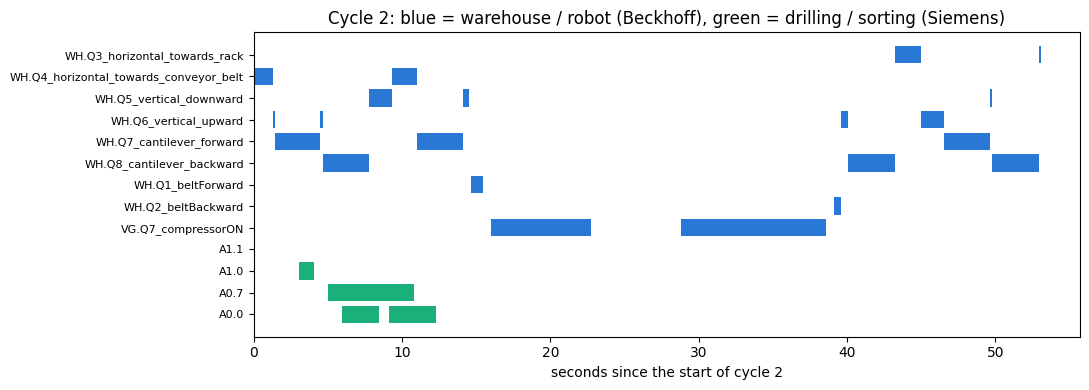

In [31]:
c2 = cycles.set_index("cycle").loc[2]
show_sig = ["WH.Q3_horizontal_towards_rack", "WH.Q4_horizontal_towards_conveyor_belt", "WH.Q5_vertical_downward",
            "WH.Q6_vertical_upward", "WH.Q7_cantilever_forward", "WH.Q8_cantilever_backward", "WH.Q1_beltForward",
            "WH.Q2_beltBackward", "VG.Q7_compressorON", "A1.1", "A1.0", "A0.7", "A0.0"]
w = acts_marked[acts_marked["signal"].isin(show_sig) & (acts_marked["end"] > c2.start_s) & (acts_marked["start"] < c2.end_s)]
fig, ax = plt.subplots(figsize=(11, 4))
for i, sig in enumerate(show_sig):
    for r in w[w["signal"] == sig].itertuples():
        ax.barh(i, min(r.end, c2.end_s) - max(r.start, c2.start_s), left=max(r.start, c2.start_s) - c2.start_s,
                color="#2a78d6" if sig.startswith(("WH", "VG")) else "#1baf7a")
ax.set_yticks(range(len(show_sig)), show_sig, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("seconds since the start of cycle 2")
ax.set_title("Cycle 2: blue = warehouse / robot (Beckhoff), green = drilling / sorting (Siemens)")
plt.tight_layout()

The warehouse fetches the pallet, the belt moves it out, the robot takes the raw part to the oven, later the robot
puts the finished part of the previous cycle on the pallet, the belt moves it back and the warehouse stores it. The
drilling and sorting stations (green) work in parallel. Part 6 showed that the warehouse + robot outputs form one
serial chain.

**Drilling cycles and robot moves**

- `MW22_PHASE`: Names of the drilling-cycle register states.
- `mw22_phases`: Phases of the drilling-station cycle register MW22.
- `drilling_cycles`: One row per oven phase (MW22 in {2,3}); part-to-part interval.
- `robot_moves`: Robot pick-and-place moves; move type from the lane barrier it clears.

In [32]:
MW22_PHASE = {0: "transition (vacuum arm down/up)", 1: "transfer, turntable, drill, conveyor, waiting",
              2: "oven phase", 3: "oven phase (variant)"}


def mw22_phases(data: dict, cfg: dict) -> pd.DataFrame:
    s = data["Siemens"].frame
    reg = cfg["phases"]["drilling_cycle_register"]
    v = s[reg].to_numpy()
    t = s["t"].to_numpy()
    change = np.r_[0, np.flatnonzero(v[1:] != v[:-1]) + 1]
    starts = t[change]
    ends = np.r_[starts[1:], t[-1]]
    out = pd.DataFrame({"value": v[change].astype(int), "start_s": starts, "end_s": ends})
    out["duration_s"] = out["end_s"] - out["start_s"]
    out["open_at_end"] = False
    out.loc[out.index[-1], "open_at_end"] = True
    out["open_at_start"] = False
    out.loc[out.index[0], "open_at_start"] = True
    out["phase"] = out["value"].map(MW22_PHASE)
    return out


def drilling_cycles(phases: pd.DataFrame) -> pd.DataFrame:
    """One row per oven phase (MW22 in {2,3}); part-to-part interval."""
    ov = phases[phases["value"].isin([2, 3])].copy()
    # merge the 2->3 sequence of the first part into one oven phase
    rows = []
    for _, r in ov.iterrows():
        if rows and abs(r["start_s"] - rows[-1]["end_s"]) < 1e-9:
            rows[-1]["end_s"] = r["end_s"]
            rows[-1]["values"] += f"{r['value']}"
        else:
            rows.append({"start_s": r["start_s"], "end_s": r["end_s"], "values": f"{r['value']}"})
    out = pd.DataFrame(rows)
    out["oven_phase_s"] = out["end_s"] - out["start_s"]
    out["part_interval_s"] = out["start_s"].diff()
    out.insert(0, "part", range(1, len(out) + 1))
    return out


def robot_moves(data: dict, cycles: pd.DataFrame) -> pd.DataFrame:
    """Robot pick-and-place moves; move type from the lane barrier it clears.

    A sorting-lane barrier (E0.3 white, E0.4 red, E0.5 blue) is LOW while a
    finished part waits in the lane. If it goes HIGH during a move, that move
    took the part from the lane (type 'lane -> pallet'); otherwise the move is
    'pallet -> oven'.
    """
    b, s = data["Beckhoff"].frame, data["Siemens"].frame
    lanes = {"E0.3": "white", "E0.4": "red", "E0.5": "blue"}
    rises = {c: [a for _, a in on_intervals(s["t"], ~s[c].astype(bool))] for c in lanes}
    rows = []
    for a, e in on_intervals(b["t"], b["VG.Q7_compressorON"]):
        lane = [lanes[c] for c, r in rises.items() if any(a <= x <= e + 0.5 for x in r)]
        rows.append({"start_s": a, "end_s": e, "duration_s": e - a,
                     "move_type": "lane -> pallet" if lane else "pallet -> oven",
                     "lane": lane[0] if lane else ""})
    out = pd.DataFrame(rows)
    out["cycle"] = np.searchsorted(cycles["start_s"].to_numpy(), out["start_s"].to_numpy(), side="right")
    return out

In [33]:
# hand over to notebooks 04-06: time-base limits, production window, stop windows, cycles, activations
rc = cfg["rule"]
mw22 = mw22_phases(data, cfg)
save_stage("03_prepared", {
    "limit": limit, "tol": tol, "min_excess": limit if rc["min_excess_s"] == "auto" else float(rc["min_excess_s"]),
    "p0": production_start(data, cfg), "end": recording_end(data), "stops": stops, "cycles": cycles,
    "acts": acts_marked, "mw22": mw22, "dcyc": drilling_cycles(mw22), "moves": robot_moves(data, cycles),
    "actuators": actuator_lists(data), "halt": stop_halt_check(data, actuator_lists(data), stops, tol),
    "sync": sync, "sync_summary": ss, "resample": resample})

## Summary of data preparation

| Decision | Basis |
|---|---|
| Analyse raw logged rows (event time); the 50 ms grid is a confirmed equivalent | notebook 04: same events up to 200 ms |
| No clock correction; cross-PLC comparisons within 0.169 s | Part 2: hand-shake edges; clock-shift test in notebook 04 |
| Production window from the first HMI reset press | notebook 02, part 6 |
| Stop windows from documented stop signals; line standstill inside them | Part 5 |
| Unit of analysis: pallet cycle (H2) and activation (one ON period of one output) | Parts 6 and 7 |

**Next:** notebook 04 - Model 1, the engineering rule.